# Домашнее задание

## Информация о кейсе

Мы хотим изменить ранжирование вакансий в поисковой выдаче. Гипотеза
продакта: релевантные вакансии окажутся выше, и соискатель будет чаще
откликаться на то, что видит в поиске. Релевантный отклик — это отклик, после
которого работодатель пригласил соискателя или посмотрел контакты в его
резюме. Приглашения входят в релевантные отклики, релевантные входят в
отклики.

Все три метрики теста — ratio-метрики: знаменатель у каждого соискателя свой.

• Целевая: конверсия из поиска в отклик = отклики / сессии с поиском. Фича
окупается при росте конверсии минимум на 2.5%.

• Guardrail: приглашения на отклик = приглашения / отклики. Если они упадут
больше чем на 4%, фичу не раскатываем.

• Информационная: доля релевантных откликов = релевантне отклики /
отклики.

• Тест пойдёт в следующем году: старт в понедельник 6 сентября 2027. На
4-ю неделю теста запланирована крупная маркетинговая кампания, которая
изменит трафик, поэтому к ней тест должен закончиться. Аудитории хватает,
чтобы разделить всех соискателей пополам.

## Задание 1

Постановка. Сформулируйте гипотезу цепочкой «изменение → механизм
→ целевая метрика». Для каждой из трёх метрик назовите числитель и знаменатель и объясните, почему она ratio. Определите единицу
рандомизации, популяцию и trigger event, для целевой и guardrail укажите тип
теста и 𝛼.

#### Изменение
Внедряем новый алгоритм ранжирования вакансий в поисковой выдаче.

#### Механизм

Релевантные вакансии выше → человек быстрее находит подходящие вакансии в рамках поисковой сессии и чаще откликается.

#### Метрики

- Целевая метрика - конверсия из поиска в отклик (>= 2.5%). `responses / sessions`
- Guardrail метрика - приглашения на отклик (падение не более 4%). `invitations / responses`
- Информационная метрика - доля релевантных откликов. `relevant_responses / responses`

Все 3 метрики - ratio, потому что единица рандомизации: сосикатель, а единица наблюдения в знаменателе - действие (поисковая сессия или отклик). Число этих действий у каждого соискателя заранее не фиксировано, поэтому оно является случайной величиной - как и числитель. Получается ratio метрики - случайная величина поделенная на случайную величину.

#### Тест

- Целевая метрика - конверсия из поиска в отклик (>= 2.5%)
> Двуосторонний тест, a = 0.05.

- Guardrail метрика - приглашения на отклик (падение не более 4%)
> Односторонний тест, a = 0.05. Проверяем только на просадку

- Информационная метрика - доля релевантных откликов
> Двусторонний с a = 0.001.

#### Единица рандомизации, популяция и Trigger event

Единица рандомизации: соискатель. Нельзя смешивать, например, по сессиям, потому что тогда контрольная и тестовая группы будут влиять друг на друга - это плохо.

Trigger event: первый заход соискателя в поиск вакансий.

Популяция: Все уникальные соискатели, совершившие trigger event за выбранное окно теста. Делим 50 на 50.

## Задание 2

MDE по данным. Проверьте качество данных и выберите, какой период
истории подходит для прогноза. Для тестов длительностью 1–4 недели
соберите для каждой метрики 𝑌𝑖 и 𝑋𝑖 на соискателя за окно и посчитайте MDE
целевой метрики и guardrail по формуле из лекции (мощность 80%), оценив
дисперсию ratio дельта-методом. Опишите, как вы определили популяцию, и
постройте график. Объясните его форму. Во сколько раз занижен MDE, если
считать каждую сессию независимым наблюдением?

### Данные

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import chisquare, norm, ttest_ind

metrics = pd.read_csv("data/user_week_metrics.csv", parse_dates=["week_start"])
users = pd.read_csv("data/users.csv", parse_dates=["reg_date"])

print("metrics:", metrics.shape)
print("users:", users.shape)
display(metrics.head())
display(users.head())

metrics: (563375, 7)
users: (160000, 4)


,week_start,user_id,sessions,search_views,responses,relevant_responses,invitations
0,2026-03-09,10000107,4,29,1,0,0
1,2026-03-09,10000206,6,5,1,1,0
2,2026-03-09,10000862,1,2,0,0,0
3,2026-03-09,10002622,2,3,0,0,0
4,2026-03-09,10003889,2,1,1,0,0


,user_id,reg_date,region_group,platform
0,18155119,2025-03-29,Остальные,app
1,61432031,2024-10-21,Москва и СПб,desktop
2,86884780,2019-12-22,Москва и СПб,app
3,25472439,2024-11-23,Москва и СПб,desktop
4,56587237,2021-07-11,Города-миллионники,desktop


### Проверка

In [2]:
print(
    "Дубли (week_start, user_id):", metrics.duplicated(["week_start", "user_id"]).sum()
)
print("Дубли users:", users["user_id"].duplicated().sum())
print("Пропуски metrics:", metrics.isna().sum().sum())
print("Пропуски users:", users.isna().sum().sum())
print("Нет в users:", len(set(metrics["user_id"]) - set(users["user_id"])))

cols = ["sessions", "search_views", "responses", "relevant_responses", "invitations"]
print("Отрицательные:", (metrics[cols] < 0).sum().to_dict())
print(
    "relevant > responses:",
    (metrics["relevant_responses"] > metrics["responses"]).sum(),
)
print(
    "invitations > relevant:",
    (metrics["invitations"] > metrics["relevant_responses"]).sum(),
)
print("sessions == 0:", (metrics["sessions"] == 0).sum())

Дубли (week_start, user_id): 0
Дубли users: 0
Пропуски metrics: 0
Пропуски users: 0
Нет в users: 0
Отрицательные: {'sessions': 0, 'search_views': 0, 'responses': 0, 'relevant_responses': 0, 'invitations': 0}
relevant > responses: 0
invitations > relevant: 0
sessions == 0: 8763


Данные чистые.

### Период

In [3]:
weekly = (
    metrics.groupby("week_start")
    .agg(
        users=("user_id", "nunique"),
        zero_sess=("sessions", lambda s: (s == 0).sum()),
        sessions=("sessions", "sum"),
        responses=("responses", "sum"),
        invitations=("invitations", "sum"),
    )
    .reset_index()
)

weekly["cr_search"] = weekly["responses"] / weekly["sessions"]
weekly["inv_per_resp"] = weekly["invitations"] / weekly["responses"]
display(weekly)

,week_start,users,zero_sess,sessions,responses,invitations,cr_search,inv_per_resp
0,2026-03-09,70920,0,267969,99690,6723,0.372021,0.067439
1,2026-03-16,72214,0,280040,104497,6939,0.373150,0.066404
2,2026-03-23,69323,0,257940,96518,6448,0.374188,0.066806
3,2026-03-30,70363,8763,195245,99272,6685,0.508448,0.067340
4,2026-04-06,73382,0,289642,108564,7375,0.374821,0.067932
5,2026-04-13,71295,0,272394,101326,6777,0.371983,0.066883
6,2026-04-20,68745,0,252175,93612,6310,0.371218,0.067406
7,2026-04-27,67133,0,243422,90958,6051,0.373664,0.066525


platform,app,desktop,mobile_web
week_start,,,
2026-03-09,119994,76501,71474
2026-03-16,125622,79265,75153
2026-03-23,116632,73648,67660
2026-03-30,47891,76436,70918
2026-04-06,129537,82202,77903
2026-04-13,121705,78083,72606
2026-04-20,112545,71584,68046
2026-04-27,109718,69431,64273


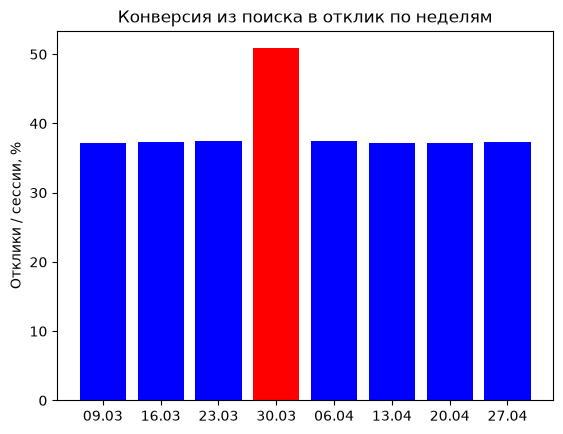

In [4]:
df = metrics.merge(users[["user_id", "platform"]], on="user_id", how="left")
display(
    df.pivot_table(
        index="week_start", columns="platform", values="sessions", aggfunc="sum"
    )
)

colors = [
    "red" if w == pd.Timestamp("2026-03-30") else "blue" for w in weekly["week_start"]
]
plt.bar(
    weekly["week_start"].dt.strftime("%d.%m"), weekly["cr_search"] * 100, color=colors
)
plt.ylabel("Отклики / сессии, %")
plt.title("Конверсия из поиска в отклик по неделям")
plt.show()

Дублей, пропусков и отрицательных значений нет, вложенность invitations <= relevant_responses <= responses выполняется. На неделе 30.03 вероятно сломалось логирование сессий в app - число сессий упало с ~120 тысяч до 48 тысяч, появились 8 763 строки с sessions == 0 (при том, что отклики особо не изменились относительно других дней). Даже если взять в расчет сессии, которые вылетели в 0, то все равно конверсия за эту неделю превышает остальные - брать ее категорически не стоит, потому что если что-то одно сломалось, то мы не знаем что еще могло быть сломано вообще. Остальные недели стабильны. Для прогноза на 1-4 недели беру непрерывный отрезок из 4 недель: 06.04 - 03.05.2026.

### MDE

In [5]:
z_target = norm.ppf(0.975) + norm.ppf(0.8)  # двусторонний, alpha=0.05, мощность 80%
z_guard = norm.ppf(0.95) + norm.ppf(0.8)  # односторонний, alpha=0.05, мощность 80%


def delta_mde(y, x, z, n_group):
    mean_y = y.mean()
    mean_x = x.mean()
    theta = mean_y / mean_x
    var_y = y.var(ddof=1)
    var_x = x.var(ddof=1)
    cov_xy = np.cov(x, y, ddof=1)[0, 1]
    var_r = (var_y - 2 * theta * cov_xy + theta**2 * var_x) / (mean_x**2)
    mde_abs = z * np.sqrt(2 * var_r / n_group)
    return theta, mde_abs / theta * 100


def mde_for(weeks):
    part = metrics[metrics["week_start"].isin(weeks)]
    per_user = part.groupby("user_id").agg(
        sessions=("sessions", "sum"),
        responses=("responses", "sum"),
        invitations=("invitations", "sum"),
    )
    per_user = per_user[per_user["sessions"] > 0]
    n = len(per_user) / 2

    cr, mde_cr = delta_mde(per_user["responses"], per_user["sessions"], z_target, n)
    inv, mde_inv = delta_mde(per_user["invitations"], per_user["responses"], z_guard, n)

    n_sess = per_user["sessions"].sum() / 2
    mde_naive_abs = z_target * np.sqrt(2 * cr * (1 - cr) / n_sess)
    mde_naive = mde_naive_abs / cr * 100

    return {
        "недель": len(weeks),
        "n на группу": int(n),
        "конв. поиска, %": cr * 100,
        "MDE конв., %": mde_cr,
        "MDE наивный, %": mde_naive,
        "занижение (раз)": mde_cr / mde_naive,
        "пригл./откл., %": inv * 100,
        "MDE пригл., %": mde_inv,
    }


clean_weeks = sorted(metrics["week_start"].unique())[4:]  # 06.04 - 27.04
mde = pd.DataFrame([mde_for(clean_weeks[:k]) for k in range(1, 5)])
display(mde.round(2))

,недель,n на группу,"конв. поиска, %","MDE конв., %","MDE наивный, %",занижение (раз),"пригл./откл., %","MDE пригл., %"
0,1,36691,37.48,3.06,1.34,2.27,6.79,6.39
1,2,54191,37.34,2.73,0.97,2.82,6.74,4.93
2,3,63416,37.28,2.59,0.81,3.22,6.74,4.28
3,4,68741,37.30,2.55,0.71,3.60,6.72,3.93


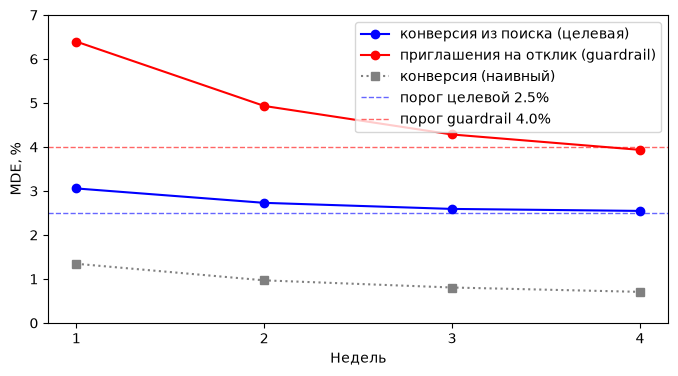

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(
    mde["недель"],
    mde["MDE конв., %"],
    marker="o",
    color="blue",
    label="конверсия из поиска (целевая)",
)
plt.plot(
    mde["недель"],
    mde["MDE пригл., %"],
    marker="o",
    color="red",
    label="приглашения на отклик (guardrail)",
)
plt.plot(
    mde["недель"],
    mde["MDE наивный, %"],
    marker="s",
    linestyle=":",
    color="gray",
    label="конверсия (наивный)",
)
plt.axhline(
    2.5,
    color="blue",
    linestyle="--",
    linewidth=1,
    alpha=0.6,
    label="порог целевой 2.5%",
)
plt.axhline(
    4.0,
    color="red",
    linestyle="--",
    linewidth=1,
    alpha=0.6,
    label="порог guardrail 4.0%",
)
plt.xticks(mde["недель"])
plt.ylim(0, 7.0)
plt.xlabel("Недель")
plt.ylabel("MDE, %")
plt.legend()
plt.show()

В анализ попадают уникальные соискатели, у которых за эти k недель была хотя бы одна сессия с поиском (sessions > 0).

MDE падает нелинейно, потому что, во первых, n с неделями растет нелинейно, во вторых, потому что MDE падает, как `1/sqrt(n)`

Если считать каждую сессию независимой, MDE занижен в ~3 раза, потому что игнорируется связь между сессиями одного соискателя.

## Задание 3

Длительность. Выберите срок эксперимента и обоснуйте: MDE и
бизнес-пороги, календарь, недельные циклы. Что вы скажете продакту: какой
эффект и какую просадку вы гарантированно заметите?

Беру 3 недели: 06.09 - 26.09.2027.

- Календарь: тест стартует в понедельник 06.09, а на 4 неделе (с 27.09) начинается крупная маркетинговая кампания. Чтобы ее не зацепить, тест нужно закончить до 26.09 включительно - максимум 3 недели.
- Недельные циклы: 3 недели - это 3 полных цикла с понедельника по воскресенье, будни и выходные сбалансированы.
- MDE и бизнес-пороги: на 1-2 неделях MDE слишком далеко от порогов (особенно по guardrail: 6.39% и 4.93% против 4%). На 3 неделях получаем 2.59% по целевой и 4.28% по guardrail - это близко к порогам 2.5% и 4%. Ждать 4 неделю нельзя из-за маркетинга, да и по целевой она почти ничего не дает (2.55% вместо 2.59%).

### Продакту

За 3 недели (06.09 - 26.09.2027) без дополнительной обработки данных мы с мощностью 80% гарантированно заметим рост конверсии из поиска в отклик от **2.59%** и просадку приглашений на отклик от **4.28%**. Это чуть хуже бизнес-порогов (2.5% и 4%), потому что 4 неделю занять нельзя из-за маркетинга.

In [7]:
# Чтобы мы могли опустить MDE до бизнес порогов
# можно попробовать убрать выбросы из данных
# например, убрать самых активных

part3 = metrics[metrics["week_start"].isin(clean_weeks[:3])]
u3 = part3.groupby("user_id").agg(
    sessions=("sessions", "sum"),
    responses=("responses", "sum"),
    invitations=("invitations", "sum"),
)
display(u3.quantile([0.5, 0.95, 0.99, 0.995, 0.999, 1.0]).round(1))

top = u3[u3["responses"] > u3["responses"].quantile(0.995)]
print("Топ 0.5% пользователей:", len(top), f"({len(top) / len(u3) * 100:.2f}%)")
print(
    "Доля в откликах:",
    round(top["responses"].sum() / u3["responses"].sum() * 100, 1),
    "%",
)

# проверка, как меняется MDE при винзоризации 99.5%
u3_win = u3.copy()
for col in ["sessions", "responses", "invitations"]:
    u3_win[col] = u3_win[col].clip(upper=u3_win[col].quantile(0.995))

n = len(u3_win) / 2
print(
    "MDE после винсоризации p99.5 (целевая):",
    round(delta_mde(u3_win["responses"], u3_win["sessions"], z_target, n)[1], 2),
    "%",
)
print(
    "MDE после винсоризации p99.5 (guardrail):",
    round(delta_mde(u3_win["invitations"], u3_win["responses"], z_guard, n)[1], 2),
    "%",
)

,sessions,responses,invitations
0.500,4.0,1.0,0.0
0.950,17.0,7.0,1.0
0.990,30.0,13.0,2.0
0.995,41.0,20.0,3.0
0.999,134.0,117.0,4.0
1.000,298.0,259.0,8.0


Топ 0.5% пользователей: 631 (0.50%)
Доля в откликах: 16.4 %
MDE после винсоризации p99.5 (целевая): 1.26 %
MDE после винсоризации p99.5 (guardrail): 3.38 %


## Задание 4

Риски. Кратко по пунктам: выбросы в ratio-метрике (как найти, что делать, как
зафиксировать правило до теста), пересечения с другими экспериментами,
маркетинговая кампания, мониторинг во время теста и условия остановки,
срезы и множественные сравнения.


### Риски

- Выбросы: нахожу по перцентилю 99.5% сессий и откликов - за 3 недели 0.5% пользователей дают 16.4% откликов и сильно увеличивают дисперсию. Можно решить винсоризацией (MDE падает до 1.26% и 3.38%). Порог и способ должен быть зафиксирован до старта теста, чтобы не было подглядывания.
- Пересечение: параллельно может быть запущен другой эксперимент, который может повлиять на этот. Например, фильтры, они могут повлиять на то, как люди будут себя вести, что помешает этому эксперименту.
- Маркетинговая кампания: стартует с 27.09 и поменяет трафик. Тест идет 06.09 - 26.09.2027 и заканчивается до нее.
- Мониторинг: если 𝑝SRM < 0.001 — стоп, что-то сломалось в рандомизации. Решение по целевой принимаю только в конце, на промежуточные p-value не опираюсь.
- Срезы: заранее фиксирую 2-3 среза - платформа, регион, новые и опытные соискатели. Для срезов использовать поправку Холма, а информационную метрику смотрю на `α = 0.001`.


## Задание 5

A/A на истории. Многократно случайно разделите соискателей на две группы
и сравните их по целевой метрике за выбранный срок тремя способами:
дельта-метод, среднее личных ratio и событийный z-тест для двух долей.
Покажите долю запусков с 𝑝 < 0.05 для каждого способа и проверьте SRM для
одного из разбиений.

### A/A

Беру то же окно и ту же популяцию, что в MDE: 3 недели 06.04 - 26.04.2026 и соискатели с `sessions > 0`. Целевая метрика - `responses / sessions`. Делаю 1000 разбиений: каждый соискатель независимо попадает в контроль или тест с вероятностью 0.5. Тест двусторонний: в A/A смотрю любые различия, а не только рост.

In [8]:
aa_weeks = clean_weeks[:3]  # 06.04 - 26.04.2026
aa_part = metrics[metrics["week_start"].isin(aa_weeks)]
aa_users = aa_part.groupby("user_id").agg(
    sessions=("sessions", "sum"),
    responses=("responses", "sum"),
)
aa_users = aa_users[aa_users["sessions"] > 0]

y = aa_users["responses"].to_numpy(dtype=float)
x = aa_users["sessions"].to_numpy(dtype=float)
r_personal = y / x


def delta_pval(y1, x1, y0, x0):
    def group_var(yg, xg):
        mx, my = xg.mean(), yg.mean()
        theta = my / mx
        vx, vy = xg.var(ddof=1), yg.var(ddof=1)
        cov = np.cov(xg, yg, ddof=1)[0, 1]
        var_r = (vy - 2 * theta * cov + theta**2 * vx) / (mx**2) / len(yg)
        return theta, var_r

    r1, v1 = group_var(y1, x1)
    r0, v0 = group_var(y0, x0)
    z = (r1 - r0) / np.sqrt(v1 + v0)
    return 2 * norm.sf(abs(z))


def ztest_prop_pval(y1, x1, y0, x0):
    s1, n1 = y1.sum(), x1.sum()
    s0, n0 = y0.sum(), x0.sum()
    p1, p0 = s1 / n1, s0 / n0
    p_pool = (s1 + s0) / (n1 + n0)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n0))
    z = (p1 - p0) / se
    return 2 * norm.sf(abs(z))


np.random.seed(42)

p_delta, p_personal, p_event = [], [], []
aa_sizes = []

for _ in range(1000):
    group = np.random.binomial(1, 0.5, size=len(y))
    m1 = group == 1
    m0 = group == 0
    aa_sizes.append((m0.sum(), m1.sum()))

    p_delta.append(delta_pval(y[m1], x[m1], y[m0], x[m0]))
    p_personal.append(ttest_ind(r_personal[m1], r_personal[m0], equal_var=False).pvalue)
    p_event.append(ztest_prop_pval(y[m1], x[m1], y[m0], x[m0]))

p_delta = np.array(p_delta)
p_personal = np.array(p_personal)
p_event = np.array(p_event)

print("Соискателей:", len(y))
print(
    f"Дельта-метод:         p < 0.05 в {(p_delta < 0.05).sum()} из 1000 ({(p_delta < 0.05).mean() * 100:.1f}%)"
)
print(
    f"Среднее личных ratio: p < 0.05 в {(p_personal < 0.05).sum()} из 1000 ({(p_personal < 0.05).mean() * 100:.1f}%)"
)
print(
    f"Событийный z-тест:    p < 0.05 в {(p_event < 0.05).sum()} из 1000 ({(p_event < 0.05).mean() * 100:.1f}%)"
)
print("Размеры групп (1 разбиение):", aa_sizes[0])
print("SRM p-value:", round(chisquare(aa_sizes[0]).pvalue, 3))
print(
    f"Общее ratio: {y.sum() / x.sum() * 100:.2f}%, среднее личных ratio: {r_personal.mean() * 100:.2f}%"
)

Соискателей: 126832
Дельта-метод:         p < 0.05 в 51 из 1000 (5.1%)
Среднее личных ratio: p < 0.05 в 54 из 1000 (5.4%)
Событийный z-тест:    p < 0.05 в 569 из 1000 (56.9%)
Размеры групп (1 разбиение): (np.int64(63381), np.int64(63451))
SRM p-value: 0.844
Общее ratio: 37.28%, среднее личных ratio: 34.04%


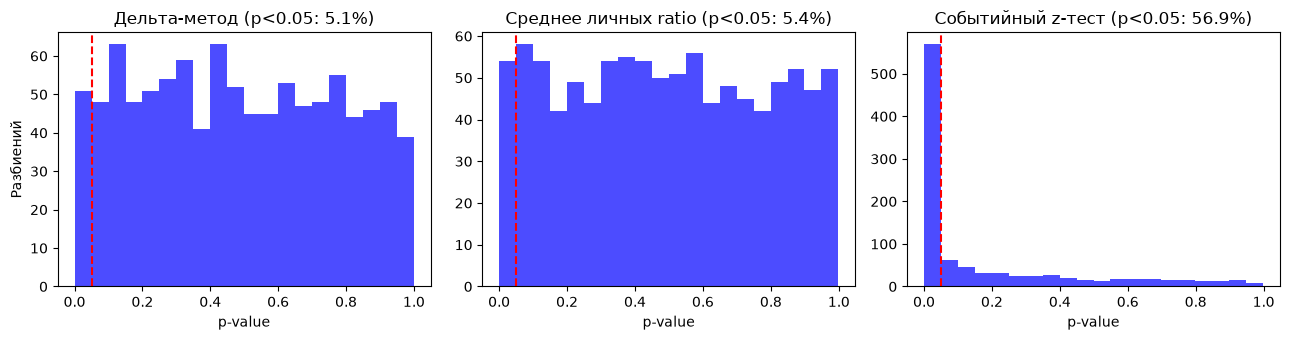

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, pvals, title in [
    (axes[0], p_delta, "Дельта-метод"),
    (axes[1], p_personal, "Среднее личных ratio"),
    (axes[2], p_event, "Событийный z-тест"),
]:
    ax.hist(pvals, bins=20, color="blue", alpha=0.7)
    ax.axvline(0.05, color="red", linestyle="--")
    ax.set_title(f"{title} (p<0.05: {(pvals < 0.05).mean() * 100:.1f}%)")
    ax.set_xlabel("p-value")

axes[0].set_ylabel("Разбиений")
plt.tight_layout()
plt.show()

Дельта метод дал p < 0.05 в 51 случае из 1000 (5.1% - около 5%), гистограмма p-value ровная, у нуля всплеска нет. Значит, критерий не находит эффект там, где его нет.

Среднее личных ratio дало p < 0.05 в 54 случаях из 1000 (5.4%). По доле ложных срабатываний тест не сломан, потому что пользователи независимы, но он проверяет другую метрику.

Событийный z-тест дал p < 0.05 в 569 случаях из 1000 (56.9% вместо 5%), на гистограмме сильный всплеск у нуля. Тест не подходит.

SRM p-value 0.844 > 0.001, группы почти одинаковые: 63 381 и 63 451. Перекоса в разбиении нет.